# Apple (AAPL) 日度股票时间序列分析

本 notebook 是 [应用时间序列分析报告](../report/report.pdf) 的可执行版本，**按报告章节的逻辑顺序**展示完整分析流程。

| notebook 小节 | 报告章节 |
|---|---|
| 1. 数据载入与清洗 | 第 1–2 节 问题重述、数据描述 |
| 2. 描述性统计与分布 | 第 3 节 收益率的进一步分析 |
| 3. 平稳性检验与数据变换 | 第 4 节 方法与模型建立 |
| 4. ARIMA 建模与预测 | 第 4 节 |
| 5. ARIMA 残差诊断与异方差 | 第 4.1 节 |
| 6. ARCH 效应检验 | 第 4.2 节 |
| 7. ARMA-GARCH 模型建立 | 第 4.3 节 |
| 8. 样本外预测验证 | 第 4.4 节 |
| 9. 模型检验与稳健性 | 第 5 节 模型检验 |

> 说明：报告中的部分数字来自 R 的 `rugarch` 包，本 notebook 统一使用 Python（`statsmodels` + `arch`）实现，个别数值（如子样本 GARCH 参数、Ljung-Box 统计量）会与报告略有出入，模型选择与结论一致。


In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")          # 让本 notebook 能 import ts_analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ts_analysis import data, eda, arima, garch, diagnostics

plt.rcParams.update({
    "figure.figsize": (12, 6), "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "font.size": 11,
    "axes.titlesize": 13, "axes.labelsize": 12,
    "axes.grid": True, "grid.alpha": 0.3, "savefig.bbox": "tight",
})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
print("ts_analysis 版本:", __import__("ts_analysis").__version__)


ts_analysis 版本: 1.0.0


## 1. 数据载入与清洗

数据来自 Kaggle 公开的苹果公司历史股票数据集，覆盖 1980-12-12 至 2025-01-03。加载时把无表头的第一列解析为日期、去重排序并建立时间索引。

In [2]:
df = data.load_dataset()
print(f"样本量: {len(df)}  区间: {df.index[0].date()} ~ {df.index[-1].date()}")
df[["Adj Close", "Volume", "log_return"]].head()

样本量: 11107  区间: 1980-12-12 ~ 2025-01-03


,Adj Close,Volume,log_return
date,,,
1980-12-12,0.098834,469033600,NaN
1980-12-15,0.093678,175884800,-0.053581
1980-12-16,0.086802,105728000,-0.076231
1980-12-17,0.088951,86441600,0.024450
1980-12-18,0.091530,73449600,0.028580


In [3]:
# 价格与交易量变量的分位数描述统计（对应报告表 2.1）
eda.descriptive_stats(df).round(4)

,Open,High,Low,Close,Adj Close,Volume
均值,24.3391,24.5982,24.0926,24.3576,23.5222,3.154341e+08
标准差,50.1668,50.6919,49.6826,50.2175,49.7679,3.348735e+08
最小值,0.0497,0.0497,0.0491,0.0491,0.0378,0.000000e+00
1%分位,0.0681,0.0687,0.0681,0.0681,0.0524,2.280589e+07
10%分位,0.1345,0.1371,0.1323,0.1345,0.1040,6.842824e+07
中位数,0.5427,0.5534,0.5346,0.5424,0.4467,2.036944e+08
90%分位,106.3820,110.3070,105.4360,107.5600,104.9969,7.115741e+08
99%分位,219.9514,221.8834,217.4590,220.6648,220.4127,1.649305e+09
最大值,258.1900,260.1000,257.6300,259.0200,259.0200,7.421641e+09


### 1.1 调整后收盘价走势

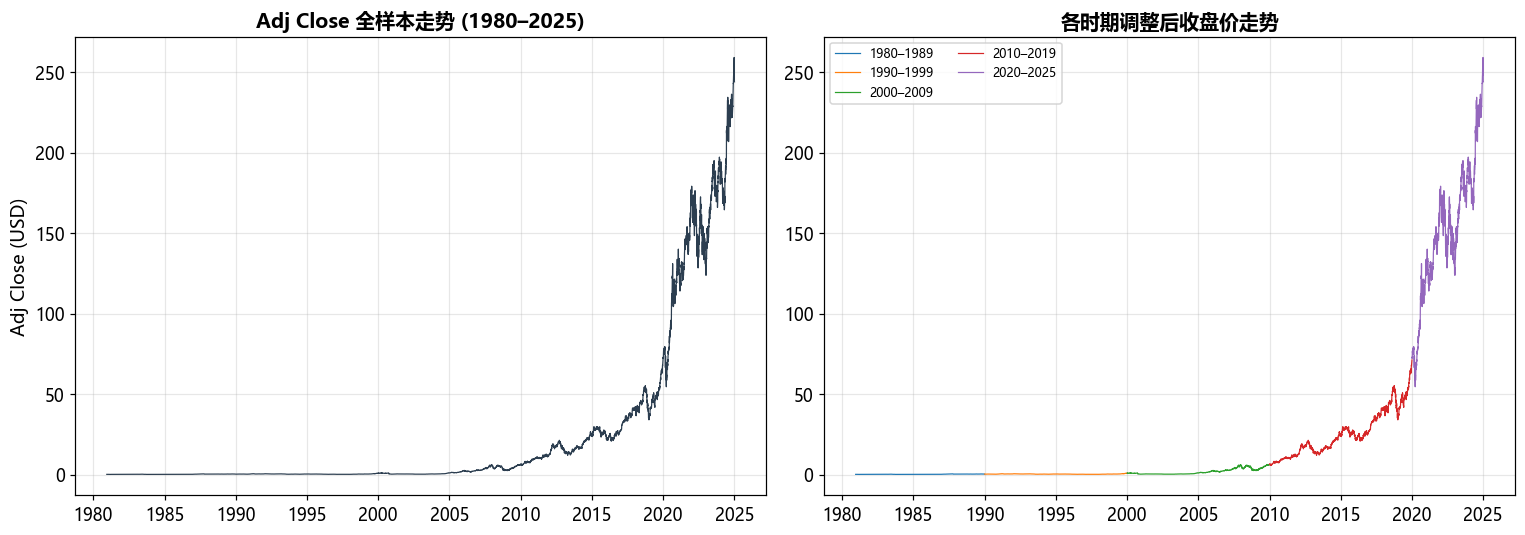

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(df.index, df["Adj Close"], color="#2c3e50", lw=0.8)
axes[0].set_title("Adj Close 全样本走势 (1980–2025)", fontweight="bold")
axes[0].set_ylabel("Adj Close (USD)")

for start, end, label in eda.DECADES:
    seg = df.loc[str(start):str(end), "Adj Close"]
    axes[1].plot(seg.index, seg.values, lw=0.8, label=label)
axes[1].set_title("各时期调整后收盘价走势", fontweight="bold")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## 2. 描述性统计与分布（报告第 3 节）

从十年分组看：价格水平从 1980 年代的 0.16 美元升至 2020 年代的 152 美元；日均收益率与波动率各时期相近；各时期收益率峰度均显著大于 3（正态基准），呈尖峰厚尾。

In [5]:
eda.stats_by_decade(df).round(4)

,时期,样本量,均价（美元）,价格范围,日均收益率（%）,收益率波动率（%）,收益率峰度
0,1980–1989,2288,0.1552,0.04–0.41,0.0901,3.1419,5.8814
1,1990–1999,2528,0.2880,0.10–0.89,0.0951,3.1846,10.3415
2,2000–2009,2515,1.8225,0.20–6.38,0.1382,3.2091,29.1575
3,2010–2019,2516,25.2214,5.79–71.17,0.1093,1.6219,4.4205
4,2020–2025,1260,152.4902,54.51–259.02,0.1177,1.9956,5.2612


### 2.1 收益率分布特征

直方图与正态曲线相比，实际数据在均值附近更集中、两端尾部更长；Q-Q 图两端偏离理论直线；按时期分箱的箱线图显示 2000 年代异常值最多、2010 年代波动最小。

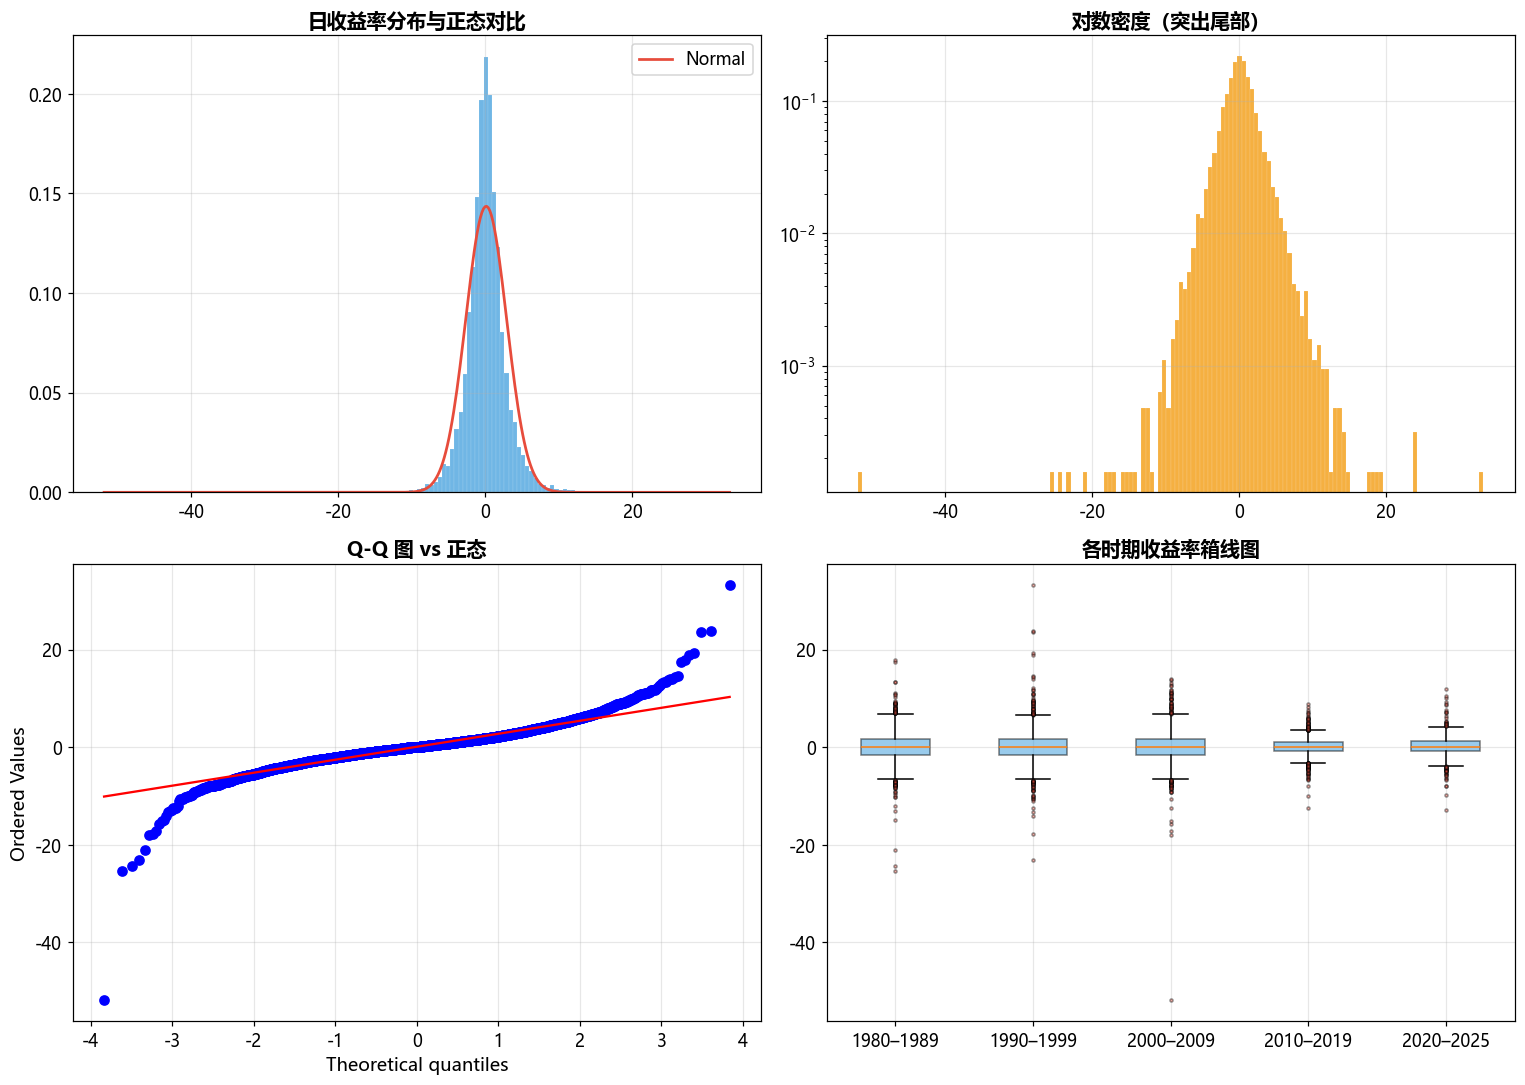

样本量     11106.0000
均值          0.0007
标准差         0.0282
偏度         -1.7489
超额峰度       48.0295
峰度         51.0295


In [6]:
from scipy import stats

r = df["return_pct"].dropna()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(r, bins=150, density=True, color="#3498db", alpha=0.7, edgecolor="white", lw=0.1)
xx = np.linspace(r.min(), r.max(), 400)
axes[0, 0].plot(xx, stats.norm.pdf(xx, r.mean(), r.std()), color="#e74c3c", lw=1.8, label="Normal")
axes[0, 0].set_title("日收益率分布与正态对比", fontweight="bold"); axes[0, 0].legend()

axes[0, 1].hist(r, bins=150, density=True, color="#f39c12", alpha=0.8, log=True, edgecolor="white", lw=0.1)
axes[0, 1].set_title("对数密度（突出尾部）", fontweight="bold")

stats.probplot(r, dist="norm", plot=axes[1, 0]); axes[1, 0].set_title("Q-Q 图 vs 正态", fontweight="bold")

groups = [df.loc[str(s):str(e), "return_pct"].dropna().values for s, e, _ in eda.DECADES]
labels = [lab for _, _, lab in eda.DECADES]
axes[1, 1].boxplot(groups, labels=labels, patch_artist=True,
                   boxprops=dict(facecolor="#3498db", alpha=0.5),
                   flierprops=dict(markerfacecolor="#e74c3c", markersize=2, alpha=0.4))
axes[1, 1].set_title("各时期收益率箱线图", fontweight="bold")
plt.tight_layout(); plt.show()

print(eda.return_summary(df["log_return"]).round(4).to_string())

## 3. 平稳性检验与数据变换

Box–Jenkins 流程：先检验趋势与平稳性。原始价格与对数价格均非平稳，对数一阶差分 `y_t = ∇ln(x_t)` 平稳，故差分阶数 `d = 1`。

In [7]:
arima.stationarity_stages(df).round(4)

,检验阶段,序列,ADF统计量,ADF p值,结论
0,A：原始,Adj Close,4.6276,1.0000,非平稳
1,B：对数变换后,ln(x_t),0.4883,0.9845,非平稳
2,C：对数一阶差分,y_t = ∇ln(x_t),-26.9075,0.0000,平稳


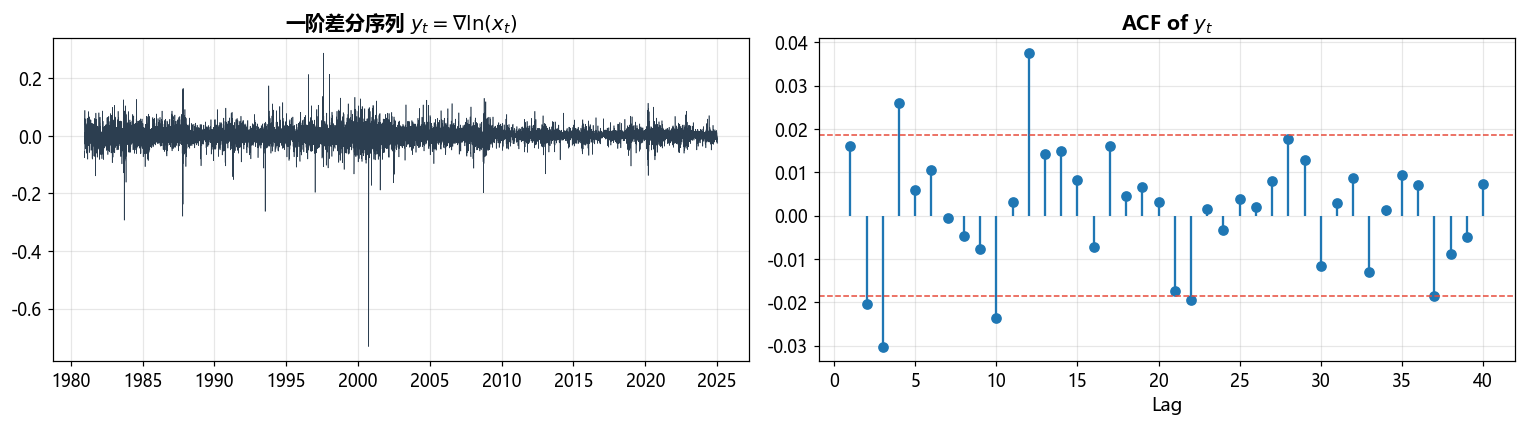

In [8]:
y = df["log_return"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(y.index, y, color="#2c3e50", lw=0.4)
axes[0].set_title(r"一阶差分序列 $y_t=\nabla\ln(x_t)$", fontweight="bold")
from statsmodels.tsa.stattools import acf, pacf
ci = 1.96 / np.sqrt(len(y))
for ax, vals, name in [(axes[1], acf(y, nlags=40), "ACF of $y_t$")]:
    ax.stem(range(1, 41), vals[1:], linefmt="-", markerfmt="o", basefmt=" ")
    ax.axhline(ci, color="#e74c3c", ls="--", lw=1); ax.axhline(-ci, color="#e74c3c", ls="--", lw=1)
    ax.set_title(name, fontweight="bold"); ax.set_xlabel("Lag")
plt.tight_layout(); plt.show()

## 4. ARIMA 建模与预测

先把样本切分为训练集（1980-12 至 2022-12，10,602 个观测）与测试集（2023-01 至 2025-01，504 个观测），在**训练集** `y_t` 上网格搜索 `p, q ∈ {0,…,4}`，按信息准则定阶。报告最终选定 `ARIMA(4,0,0)`（价格序列上的 `ARIMA(1,4,0)`）：参数全部显著且 BIC 更小。

In [9]:
sp = data.train_test_split(df, test_size=504)

sel = arima.select_arima(sp.train_return, max_order=4)
print("AIC 最优:", sel.order, " AIC=%.2f" % sel.aic)
print(sel.table.head(5).round(2).to_string(index=False))

fit = arima.fit_arima(sp.train_return, order=(4, 0, 0))
print("\n选定 ARIMA(4,0,0):  AIC=%.2f  BIC=%.2f" % (fit.aic, fit.bic))
print(fit.summary().tables[1])

AIC 最优: (4, 0, 4)  AIC=-45213.84
    order       aic       bic
(4, 0, 4) -45213.84 -45141.15
(4, 0, 0) -45211.30 -45167.68
(0, 0, 4) -45211.11 -45167.50
(1, 0, 4) -45209.89 -45159.01
(4, 0, 1) -45209.27 -45158.39



选定 ARIMA(4,0,0):  AIC=-45211.30  BIC=-45167.68
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      2.349      0.019       0.000       0.001
ar.L1          0.0158      0.007      2.375      0.018       0.003       0.029
ar.L2         -0.0193      0.006     -3.193      0.001      -0.031      -0.007
ar.L3         -0.0302      0.007     -4.426      0.000      -0.044      -0.017
ar.L4          0.0267      0.007      3.717      0.000       0.013       0.041
sigma2         0.0008   2.69e-06    305.234      0.000       0.001       0.001


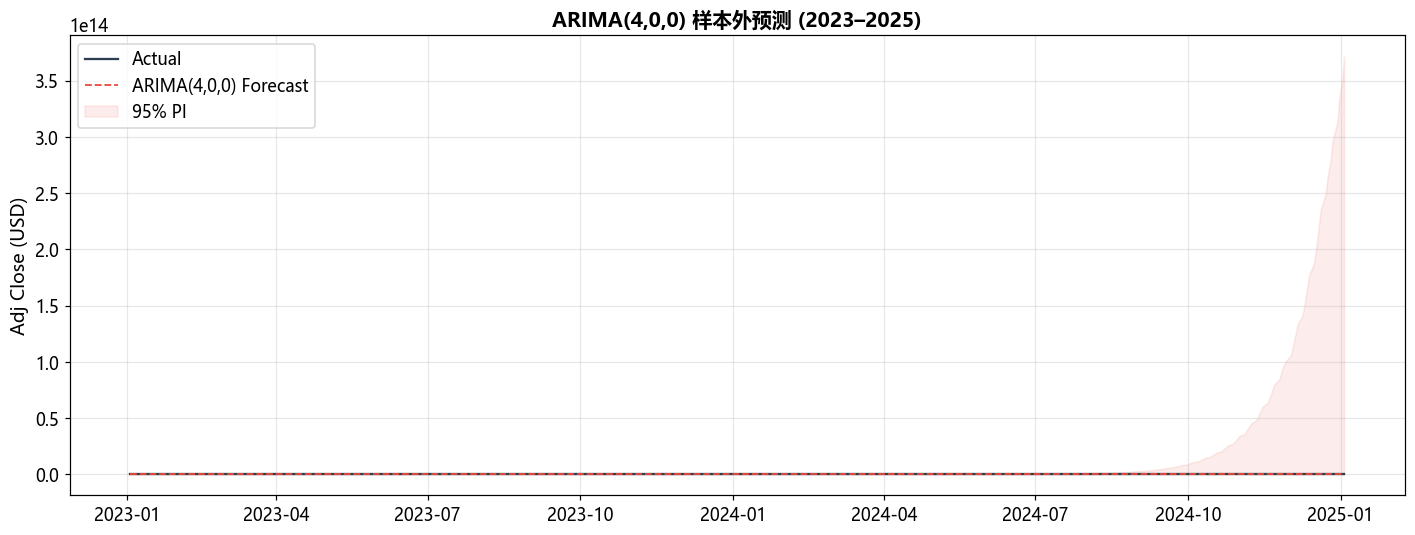

不同预测步长的误差:
 horizon    RMSE     MAE    MAPE
      63 17.3780 15.6157 10.3565
     126 29.0789 26.0893 15.6358
     252 33.7079 31.4382 17.8030
     504 39.9674 36.3566 18.4393


In [10]:
fc = arima.forecast_prices(fit, sp.last_log_price, steps=504)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(sp.test_price.index, sp.test_price.values, color="#2c3e50", lw=1.5, label="Actual")
ax.plot(sp.test_price.index, fc["forecast"], color="#e74c3c", ls="--", lw=1.2, label="ARIMA(4,0,0) Forecast")
ax.fill_between(sp.test_price.index, fc["lower"], fc["upper"], color="#e74c3c", alpha=0.1, label="95% PI")
ax.set_title("ARIMA(4,0,0) 样本外预测 (2023–2025)", fontweight="bold")
ax.set_ylabel("Adj Close (USD)"); ax.legend(); plt.tight_layout(); plt.show()

print("不同预测步长的误差:")
print(arima.horizon_rmse(fit, sp.last_log_price, sp.test_price).round(4).to_string(index=False))

## 5. ARIMA 残差诊断与异方差

若残差同方差，其对平方的 Ljung-Box 应不显著。实际结果强烈拒绝原假设，说明残差存在 ARCH 效应，需要转入 GARCH 类模型。

In [11]:
resid = fit.resid
z_arima = (resid - resid.mean()) / resid.std()
print("残差平方的 Ljung-Box 检验 (H0: 无自相关):")
print(garch.ljung_box(z_arima**2).round(4).to_string())

残差平方的 Ljung-Box 检验 (H0: 无自相关):
         统计量   p值
lag              
5    44.4225  0.0
10   60.6260  0.0
15   66.5787  0.0
20   76.6713  0.0


## 6. 波动聚集与 ARCH 效应检验

对收益率平方做 Ljung-Box、对收益率做 ARCH-LM 检验，两者都强烈拒绝“无异方差”，确认存在显著 ARCH 效应；收益率平方的 ACF 缓慢衰减，是 GARCH 过程典型特征。

In [12]:
print("收益率平方的 Ljung-Box 检验:")
print(garch.ljung_box(df["log_return"]**2).round(4).to_string())
print("\nARCH-LM 检验 (12 阶):", {k: round(v, 4) for k, v in garch.arch_lm_test(df["log_return"], 12).items()})

收益率平方的 Ljung-Box 检验:


         统计量   p值
lag              
5    53.1384  0.0
10   72.8002  0.0
15   79.5331  0.0
20   91.0650  0.0

ARCH-LM 检验 (12 阶): {'TR2': 61.3826, 'pvalue': 0.0, 'f_stat': 5.1376, 'f_pvalue': 0.0}


## 7. ARMA-GARCH 模型建立

比较 ARCH(1)、GARCH(1,1)、GARCH(2,1)、AR(1)-GARCH(1,1)，以 AIC 与对数似然为准。`GARCH(1,1)` 胜出，条件分布取 `t` 以刻画厚尾。``

In [13]:
cmp = garch.compare_models(df["log_return"])
cmp[["模型", "AIC", "BIC", "对数似然"]].round(4)

,模型,AIC,BIC,对数似然
0,"GARCH(1,1)",-51925.9619,-51896.7009,25966.9809
1,"GARCH(2,1)",-51901.2107,-51864.6345,25955.6053
2,ARCH(1),-50804.2895,-50782.3438,25405.1448
3,"AR(1)-GARCH(1,1)",11170.4824,11214.3733,-5579.2412


GARCH(1,1) 参数: {'omega': 1.6e-05, 'alpha[1]': 0.1, 'beta[1]': 0.88, 'nu': 4.744594}
波动率持久性 α+β = 0.9800
无条件标准差 = 2.8206%


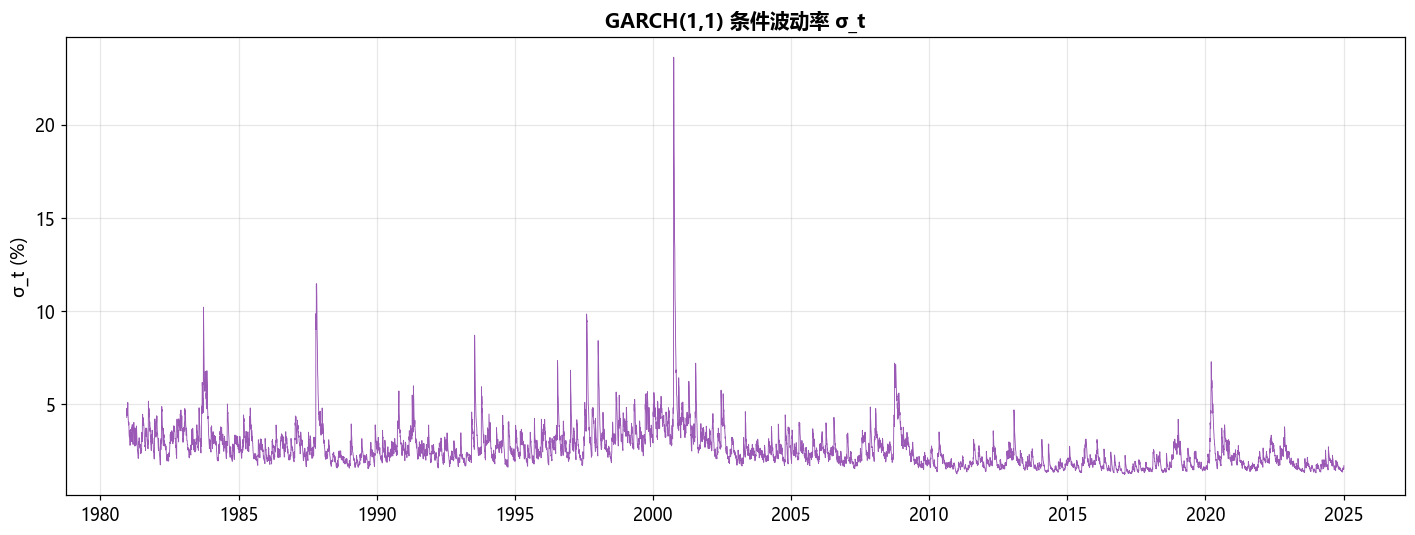

In [14]:
best = garch.fit_garch(df["log_return"])
print("GARCH(1,1) 参数:", {k: round(float(v), 6) for k, v in best.params.items()})
print("波动率持久性 α+β = %.4f" % garch.persistence(best))
print("无条件标准差 = %.4f%%" % (garch.unconditional_volatility(best) * 100))

sigma = garch.conditional_volatility(best)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(sigma.index, sigma * 100, color="#9b59b6", lw=0.6)
ax.set_title("GARCH(1,1) 条件波动率 σ_t", fontweight="bold")
ax.set_ylabel("σ_t (%)"); plt.tight_layout(); plt.show()

## 8. 样本外预测验证

训练集为 1980-12 至 2022-12（10,602 个观测），测试集为 2023-01 至 2025-01（504 个观测）。以 `|r_t|` 作为波动率代理，比较 GARCH 预测与常数历史波动率基准。

训练集参数: {'omega': 3e-06, 'alpha[1]': 0.055307, 'beta[1]': 0.943287, 'nu': 4.817803}  持久性=0.9986


               模型  RMSE(%)  MAE(%)
常数波动率(历史平均=1.95%)   1.2996  1.1539
       GARCH(1,1)   2.4763  2.3305


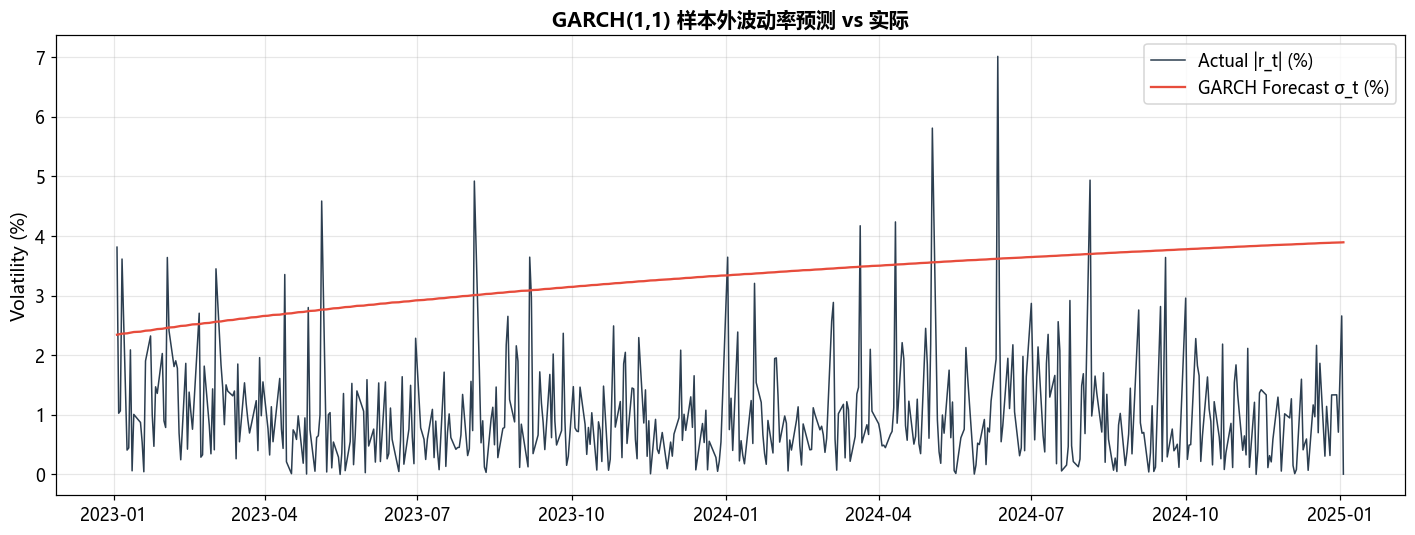

In [15]:
res_tr = garch.fit_garch(sp.train_return)
print("训练集参数:", {k: round(float(v), 6) for k, v in res_tr.params.items()},
      " 持久性=%.4f" % garch.persistence(res_tr))

sigma_fc = garch.forecast_volatility(res_tr, horizon=len(sp.test_return))
const_level = float(np.abs(sp.train_return).mean())
tab = garch.evaluate_volatility_forecast(sp.test_return, sigma_fc, constant_level=const_level)
tab["RMSE(%)"] = tab["RMSE"] * 100; tab["MAE(%)"] = tab["MAE"] * 100
print(tab[["模型", "RMSE(%)", "MAE(%)"]].round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(sp.test_price.index, np.abs(sp.test_return.values) * 100, color="#2c3e50", lw=1.0, label="Actual |r_t| (%)")
ax.plot(sp.test_price.index, sigma_fc * 100, color="#e74c3c", lw=1.5, label="GARCH Forecast σ_t (%)")
ax.set_title("GARCH(1,1) 样本外波动率预测 vs 实际", fontweight="bold")
ax.set_ylabel("Volatility (%)"); ax.legend(); plt.tight_layout(); plt.show()

## 9. 模型检验与稳健性

对 GARCH(1,1) 的标准化残差 `z_t` 做白噪声检验：其平方的 Ljung-Box 均不显著，说明 ARCH 效应已被充分吸收。稳健性方面检查子样本估计、分布替换与杠杆效应。

In [16]:
z = garch.standardized_residuals(best)
print("标准化残差的白噪声检验:")
print(diagnostics.residual_white_noise(z).round(4).to_string())
print("\nJarque-Bera 正态检验:", {k: round(v, 4) for k, v in diagnostics.jarque_bera(z).items()})

标准化残差的白噪声检验:


        残差统计量   残差 p值  残差平方统计量  残差平方 p值
滞后阶数                                   
5     24.5155  0.0002   2.3822   0.7941
10    26.5413  0.0031   4.7057   0.9100
15    35.4157  0.0021   8.0995   0.9197
20    38.8877  0.0069   9.6808   0.9736

Jarque-Bera 正态检验: {'stat': 30130.1325, 'pvalue': 0.0}


In [17]:
print("子样本稳健性:")
print(diagnostics.subsample_garch(df["log_return"],
      [("1980–2000", "1980", "2000"), ("2000–2022", "2000", "2022")]).round(4).to_string(index=False))
print("\n条件分布替换:")
print(diagnostics.compare_distributions(df["log_return"]).round(2).to_string(index=False))
print("\nEGARCH 杠杆效应参数:", {k: round(float(v), 5) for k, v in diagnostics.egarch_leverage(df["log_return"]).items()})

子样本稳健性:
      子样本  样本量     α1     β1  α1+β1
1980–2000 5067 0.0922 0.8487 0.9409
2000–2022 5787 0.1000 0.8800 0.9800

条件分布替换:
   分布       AIC       BIC     对数似然
    t -51925.96 -51896.70 25966.98
skewt -51923.96 -51887.39 25966.98
  ged -51559.25 -51529.99 25783.63



EGARCH 杠杆效应参数: {'omega': -0.06824, 'alpha[1]': 0.13421, 'gamma[1]': -0.03241, 'beta[1]': 0.98953, 'nu': 4.94755}


## 小结

- 价格序列非平稳，对数一阶差分 `y_t = ∇ln(x_t)` 平稳，差分阶数 `d = 1`。
- 条件均值用 `ARIMA(4,0,0)`（等价于价格上的 `ARIMA(1,4,0)`）刻画，但残差存在显著 ARCH 效应。
- 条件方差用 `GARCH(1,1)` + `t` 分布刻画，捕获了波动率聚集与厚尾。
- 样本外预测中，GARCH 的点预测精度不及常数波动率，但其优势在于提供时变波动率与分位数风险度量。

完整推导与讨论见 [报告 PDF](../report/report.pdf)。